# 선형회귀 복습

In [1]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler  # 정규화클래스
from sklearn.model_selection import train_test_split

In [8]:
# 데이터전처리
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0, 
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5, 
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5, 
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0, 
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0, 
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
    )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0, 
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0, 
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0, 
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0, 
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0, 
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0, 
    1000.0, 1000.0]
    )

In [9]:
#훈련데이터, 테스트 데이터 분리
train_data,test_data,train_label,test_label = train_test_split(perch_length,perch_weight)

In [14]:
#훈련데이터는 2차원 데이터가 되어야 함.
# train_data[:2]
# test_data[:2]
#훈련데이터 2차원 데이터 배열 변경
train_data = train_data.reshape(-1,1)
train_data[:5]
test_data = test_data.reshape(-1,1)
test_data[:5]

array([[24.],
       [23.],
       [18.],
       [43.],
       [40.]])

In [18]:
#데이터 학습
lr = LinearRegression()

#선형회귀
lr.fit(train_data,train_label)

#데이터 예측
predict = lr.predict(test_data)
print("예측무게: ",predict)

#정확도
score= lr.score(train_data,train_label)
score2= lr.score(test_data,test_label)
print("train정확도: ",score)
print("test정확도: ",score2)

예측무게:  [ 228.00078676  191.19956162    7.19343594  927.22406438  816.82038896
  172.79894906  816.82038896  816.82038896   80.79588621 -151.05183216
  706.41671355  228.00078676  816.82038896  -59.04876931]
train정확도:  0.9044025839248163
test정확도:  0.9443611632131451


In [20]:
# 기울기
print(lr.coef_,lr.intercept_)

[36.80122514] -655.2286165431278


In [27]:
#예측값 입력받기
in_data = input("농어의 길이를 입력하세요 .예)27")
in_data = float(in_data)
result = lr.predict([[in_data]])
print(f"농어 예측무게: {result[0]:.2f}g")

농어 예측무게: 338.40g


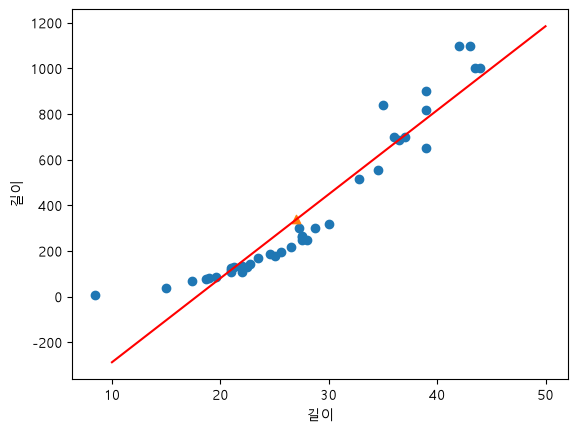

In [28]:
# 산점도 그래프
plt.scatter(train_data,train_label)
plt.scatter(in_data,result[0],marker="^")

plt.plot([10,50],[10*lr.coef_+lr.intercept_,50*lr.coef_+lr.intercept_],color='r')
plt.xlabel('길이')
plt.ylabel('길이')
plt.show()